# PRAKTIKUM 01 — Python dan Eksplorasi Data

**Seri:** *From Data to Machine Learning*  
**Moda:** praktik mandiri dan diskusi  
**Cakupan:** dasar Python, NumPy, Pandas, pengenalan data tabular, eksplorasi data, dan interpretasi visualisasi.

> **Posisi dalam rangkaian praktikum:** Modul 01 membahas cara membaca, memanipulasi, memeriksa, dan memahami dataset. Transformasi representasi fitur dipelajari pada Modul 02; imputasi, scaling, dan pipeline pada Modul 03; pemodelan klasifikasi pada Modul 04.

**Data utama (asli dari paket workshop):** `Tab.csv` (5 baris) dan `Social_Network_Ads.csv` (400 baris). Angka pada `Tab.csv` merupakan **data latihan**, bukan angka resmi terkini.

Notebook terdiri atas **materi + demonstrasi + praktik terbimbing + latihan + kunci jawaban**. Jalankan sel berurutan menggunakan **Kernel → Restart & Run All**.

## A. Capaian pembelajaran

Setelah menyelesaikan praktikum, mahasiswa mampu:

1. Membedakan *variabel*, *list*, *dictionary*, *array*, *Series*, dan *DataFrame*.
2. Melakukan operasi numerik berbasis NumPy dan menjelaskan dimensi (*shape*) data.
3. Membaca file CSV dan mengidentifikasi baris, kolom, indeks, tipe data, serta skala observasi.
4. Memilih, menyaring, mengurutkan, dan mengagregasi data menggunakan Pandas.
5. Melakukan pemeriksaan eksploratif terhadap *missing values*, duplikasi, distribusi, dan komposisi label.
6. Membuat serta menjelaskan grafik dasar tanpa menarik klaim kausalitas yang tidak didukung data.
7. Membedakan fitur (*input*) dan target (*output*) pada masalah klasifikasi sederhana.

### Peta alur

`Python dasar → NumPy → Pandas → Eksplorasi Tab.csv → Eksplorasi data Ads → Visualisasi → Fitur vs target → Latihan & pembahasan`

### Aturan pembelajaran

- **Amati** output setiap sel; jangan hanya menjalankan kode.
- **Jelaskan** apa yang ditunjukkan output: tipe, dimensi, satuan, serta keterbatasannya.
- **Ubah** parameter contoh dan prediksi hasil sebelum menjalankan ulang.
- Semua latihan memiliki jawaban pada bagian akhir. Kerjakan dahulu sebelum melihat jawabannya.

## B. Menyiapkan lingkungan dan data

**Paket minimum:** Python 3.10+, `numpy`, `pandas`, `matplotlib`, `ipykernel` / Jupyter Notebook.

Jika belum terpasang, jalankan di terminal: `python -m pip install numpy pandas matplotlib jupyterlab`.

**Struktur yang didukung:**

```text
Praktikum_01/
├── 01_Python_dan_Eksplorasi_Data_Modul.ipynb
└── data/
    ├── Tab.csv
    └── Social_Network_Ads.csv
```

Notebook juga mencari kedua file pada jalur asli `praktikum/data/` dari paket workshop. **Tidak menggunakan data buatan otomatis:** apabila file tidak ada, pesan kesalahan akan menunjukkan folder yang harus diperbaiki.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Cari dua dataset asli pada struktur modul mandiri atau paket workshop.
REQUIRED = ('../data/Tab.csv', '../data/Social_Network_Ads.csv')
BASES = [Path.cwd(), *Path.cwd().parents]
RELATIVE_DIRS = (
    Path('data'),
    Path('praktikum/data'),
    Path('Workshop_From_Data_to_ML/praktikum/data'),
)

DATA_DIR = next(
    (base / relative for base in BASES for relative in RELATIVE_DIRS
     if all((base / relative / filename).is_file() for filename in REQUIRED)),
    None
)
if DATA_DIR is None:
    raise FileNotFoundError(
        'Dataset tidak ditemukan. Simpan Tab.csv dan Social_Network_Ads.csv '
        'pada folder data/ di samping notebook, atau buka notebook dari paket workshop.'
    )

print('Python  :', sys.version.split()[0])
print('NumPy   :', np.__version__)
print('Pandas  :', pd.__version__)
print('Folder data:', DATA_DIR.resolve())
print('Data tersedia:', [p.name for p in DATA_DIR.iterdir() if p.name in REQUIRED])

Python  : 3.10.18
NumPy   : 2.0.1
Pandas  : 2.3.1
Folder data: /Users/masaboe/Documents/NGAJAR/ngudiWaluyo2026/final_release/Workshop_From_Data_to_ML/praktikum/data
Data tersedia: []


### Cek kesiapan

Pastikan dua file CSV terdeteksi. Sel berikut memeriksa file sebelum dipakai, agar error karena path tidak tertukar dengan error pengolahan data.

In [2]:
for filename in REQUIRED:
    path = DATA_DIR / filename
    print(f'{filename:25s} | ada={path.exists()} | ukuran={path.stat().st_size:,} byte')

../data/Tab.csv           | ada=True | ukuran=172 byte
../data/Social_Network_Ads.csv | ada=True | ukuran=10,926 byte


## C. Dasar Python untuk data

### C1. Variabel, tipe data, dan operasi

Python menyimpan nilai melalui **variabel**. Tipe yang sering muncul pada pengolahan data: `int` (bilangan bulat), `float` (desimal), `str` (teks), dan `bool` (benar/salah). Nama variabel sebaiknya menjelaskan maknanya.

In [3]:
nama = 'Sampel A'
umur = 21
nilai = 86.5
lulus = nilai >= 70

print('Nama     :', nama, '| tipe:', type(nama).__name__)
print('Umur     :', umur, '| tipe:', type(umur).__name__)
print('Nilai    :', nilai, '| tipe:', type(nilai).__name__)
print('Lulus    :', lulus, '| tipe:', type(lulus).__name__)

Nama     : Sampel A | tipe: str
Umur     : 21 | tipe: int
Nilai    : 86.5 | tipe: float
Lulus    : True | tipe: bool


**Interpretasi:** ekspresi `nilai >= 70` menghasilkan `True` atau `False`, bukan angka probabilitas. Operasi Python mengikuti tipe nilai; misalnya `'5'` adalah teks dan berbeda dari `5` (integer).

### C2. List, indeks, slicing, dan dictionary

- `list` menyimpan kumpulan nilai berurutan; indeks Python mulai dari **0**.
- `slicing` `[awal:akhir]` menyertakan indeks awal tetapi **tidak** menyertakan indeks akhir.
- `dict` menyimpan pasangan *key:value*, cocok untuk satu catatan sederhana.

In [4]:
nilai_mahasiswa = [75, 90, 82, 88]
mahasiswa = {'nama': 'Rina', 'usia': 20, 'prodi': 'Informatika'}

print('Semua nilai       :', nilai_mahasiswa)
print('Nilai pertama     :', nilai_mahasiswa[0])
print('Dua nilai pertama :', nilai_mahasiswa[:2])
print('Nilai terakhir    :', nilai_mahasiswa[-1])
print('Nama dari dict    :', mahasiswa['nama'])
print('Rata-rata list    :', sum(nilai_mahasiswa) / len(nilai_mahasiswa))

Semua nilai       : [75, 90, 82, 88]
Nilai pertama     : 75
Dua nilai pertama : [75, 90]
Nilai terakhir    : 88
Nama dari dict    : Rina
Rata-rata list    : 83.75


### C3. Percabangan, perulangan, dan fungsi

Ketiganya membantu membuat analisis yang dapat dipakai ulang. Fungsi `return` mengembalikan nilai sehingga hasilnya dapat disimpan atau digunakan dalam perhitungan lain.

In [5]:
def kategori_nilai(skor):
    if skor >= 85:
        return 'Sangat baik'
    elif skor >= 70:
        return 'Baik'
    return 'Perlu belajar'

for skor in nilai_mahasiswa:
    print(f'Nilai {skor:3d} → {kategori_nilai(skor)}')

print('Kategori nilai 90:', kategori_nilai(90))

Nilai  75 → Baik
Nilai  90 → Sangat baik
Nilai  82 → Baik
Nilai  88 → Sangat baik
Kategori nilai 90: Sangat baik


**Coba sendiri:** ubah batas `85` menjadi `80`, lalu prediksi perubahan keluaran. Kategori pada contoh ini adalah aturan latihan, **bukan** standar penilaian akademik universitas.

## D. NumPy: array dan operasi numerik

### D1. Mengapa array?

List Python digunakan untuk menyimpan elemen secara umum. **NumPy array** mendukung operasi element-wise (*per elemen*), misalnya membagi seluruh berat dengan kuadrat tinggi secara serentak.

Rumus indeks massa tubuh (IMT/BMI) berikut hanya dipakai untuk memperagakan operasi numerik, **bukan** diagnosis atau penilaian klinis.

In [6]:
tinggi_m = np.array([1.60, 1.70, 1.75])
berat_kg = np.array([50, 65, 72])

bmi = berat_kg / (tinggi_m ** 2)
print('Tinggi (m) :', tinggi_m)
print('Berat (kg) :', berat_kg)
print('BMI        :', np.round(bmi, 2))
print('Shape      :', bmi.shape)
print('dtype      :', bmi.dtype)

Tinggi (m) : [1.6  1.7  1.75]
Berat (kg) : [50 65 72]
BMI        : [19.53 22.49 23.51]
Shape      : (3,)
dtype      : float64


**Cara membaca:** `shape = (3,)` berarti array satu dimensi dengan tiga elemen. Hasil `bmi` terdiri atas tiga angka karena masing-masing berat dibagi kuadrat tinggi pada posisi yang sama.

### D2. Vektor 1D dan matriks 2D

Dalam analisis data, *shape* penting untuk mengenali banyaknya baris dan kolom. NumPy tidak memberi arti otomatis pada dimensi; maknanya tergantung bagaimana kita mengatur data.

In [7]:
# Tiap baris: satu observasi; tiap kolom: [tinggi_m, berat_kg]
matriks_pengukuran = np.column_stack([tinggi_m, berat_kg])

print('Array 1D tinggi :', tinggi_m.shape)
print('Array 2D data   :', matriks_pengukuran.shape)
print('Baris pertama   :', matriks_pengukuran[0])
print('Berat kolom ke-2:', matriks_pengukuran[:, 1])
display(pd.DataFrame(matriks_pengukuran, columns=['Tinggi (m)', 'Berat (kg)']))

Array 1D tinggi : (3,)
Array 2D data   : (3, 2)
Baris pertama   : [ 1.6 50. ]
Berat kolom ke-2: [50. 65. 72.]


,Tinggi (m),Berat (kg)
0,1.60,50.0
1,1.70,65.0
2,1.75,72.0


**Interpretasi:** `(3, 2)` berarti **3 observasi × 2 variabel**. Ini adalah pengantar konsep baris dan kolom; representasi *feature space* akan dibahas lebih jauh pada Praktikum 02.

### D3. Statistik sederhana dari NumPy

In [8]:
print('Rata-rata berat  :', np.mean(berat_kg))
print('Median berat     :', np.median(berat_kg))
print('Minimum maksimum :', np.min(berat_kg), np.max(berat_kg))
print('Jumlah observasi :', len(berat_kg))

Rata-rata berat  : 62.333333333333336
Median berat     : 65.0
Minimum maksimum : 50 72
Jumlah observasi : 3


## E. Pandas: membaca dan memahami DataFrame

### E1. Membaca `Tab.csv`

CSV merupakan berkas teks tabular. `pd.read_csv()` membentuk **DataFrame**. Pada `Tab.csv`, kolom pertama adalah **kode negara**, sehingga digunakan sebagai indeks dengan `index_col=0`.

> **Peringatan data:** nilai `Populasi` dan `Area` pada `Tab.csv` hanya contoh pengajaran. Tidak ada definisi tahun atau satuan pada berkas; jangan menafsirkannya sebagai statistik negara aktual.

In [9]:
tab = pd.read_csv(DATA_DIR / 'Tab.csv', index_col=0)

print('Tabel negara:')
display(tab)
print('Shape (baris, kolom):', tab.shape)
print('Nama kolom:', tab.columns.tolist())
print('Indeks:', tab.index.tolist())

Tabel negara:


,Negara,Populasi,Area,Ibukota
IN,Indonesia,250,123456,Jakarta
MA,Malaysia,25,3456,KL
SI,Singapura,15,456,Singapura
JP,Jepang,60,5678,Tokyo
TH,Thailand,45,678,Bangkok


Shape (baris, kolom): (5, 4)
Nama kolom: ['Negara', 'Populasi', 'Area', 'Ibukota']
Indeks: ['IN', 'MA', 'SI', 'JP', 'TH']


**Interpretasi:** `tab.shape` adalah `(5, 4)` karena kode negara menjadi indeks, bukan kolom data biasa. `DataFrame` memiliki indeks baris, nama kolom, dan tipe data per kolom.

### E2. Melihat bagian dataset dan tipe data

`head(n)` atau `tail(n)` **hanya membatasi tampilan**, bukan mengurangi data asli. `info()` merangkum ukuran, tipe data dan jumlah nilai non-null.

In [10]:
print('Dua baris awal:')
display(tab.head(2))
print('Dua baris akhir:')
display(tab.tail(2))
print('Tipe data setiap kolom:')
display(tab.dtypes.to_frame('dtype'))
print('Ringkasan info():')
tab.info()

Dua baris awal:


,Negara,Populasi,Area,Ibukota
IN,Indonesia,250,123456,Jakarta
MA,Malaysia,25,3456,KL


Dua baris akhir:


,Negara,Populasi,Area,Ibukota
JP,Jepang,60,5678,Tokyo
TH,Thailand,45,678,Bangkok


Tipe data setiap kolom:


,dtype
Negara,object
Populasi,int64
Area,int64
Ibukota,object


Ringkasan info():
<class 'pandas.core.frame.DataFrame'>
Index: 5 entries, IN to TH
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Negara    5 non-null      object
 1   Populasi  5 non-null      int64 
 2   Area      5 non-null      int64 
 3   Ibukota   5 non-null      object
dtypes: int64(2), object(2)
memory usage: 200.0+ bytes


### E3. Memilih baris dan kolom

- `df['kolom']` → satu kolom, menghasilkan `Series`.
- `df[['kolom1', 'kolom2']]` → beberapa kolom, menghasilkan `DataFrame`.
- `.loc[label]` → mengambil baris berdasarkan **label indeks**.
- `.iloc[posisi]` → mengambil baris berdasarkan **posisi angka**.

In [11]:
print('Kolom Negara sebagai Series:')
display(tab['Negara'])
print('Dua kolom sebagai DataFrame:')
display(tab[['Negara', 'Ibukota']])
print('Baris dengan label indeks IN (.loc):')
display(tab.loc[['IN']])
print('Baris pada posisi 0 (.iloc):')
display(tab.iloc[[0]])

Kolom Negara sebagai Series:


IN    Indonesia
MA     Malaysia
SI    Singapura
JP       Jepang
TH     Thailand
Name: Negara, dtype: object

Dua kolom sebagai DataFrame:


,Negara,Ibukota
IN,Indonesia,Jakarta
MA,Malaysia,KL
SI,Singapura,Singapura
JP,Jepang,Tokyo
TH,Thailand,Bangkok


Baris dengan label indeks IN (.loc):


,Negara,Populasi,Area,Ibukota
IN,Indonesia,250,123456,Jakarta


Baris pada posisi 0 (.iloc):


,Negara,Populasi,Area,Ibukota
IN,Indonesia,250,123456,Jakarta


**Perhatikan:** `.loc['IN']` memilih label `IN`, sedangkan `.iloc[0]` memilih posisi pertama. Kebetulan keduanya menunjuk baris yang sama pada dataset ini, tetapi konsepnya berbeda.

### E4. Filter, pengurutan, dan statistik

Filter `tab['Populasi'] > 30` menghasilkan nilai boolean per baris. Boolean tersebut dapat digunakan untuk menyeleksi observasi.

In [12]:
print('Negara dengan nilai populasi latihan > 30:')
display(tab.loc[tab['Populasi'] > 30, ['Negara', 'Populasi']])

print('Urutan berdasarkan nilai Populasi terbesar:')
display(tab.sort_values('Populasi', ascending=False))

print('Ringkasan kolom numerik:')
display(tab[['Populasi', 'Area']].describe())

Negara dengan nilai populasi latihan > 30:


,Negara,Populasi
IN,Indonesia,250
JP,Jepang,60
TH,Thailand,45


Urutan berdasarkan nilai Populasi terbesar:


,Negara,Populasi,Area,Ibukota
IN,Indonesia,250,123456,Jakarta
JP,Jepang,60,5678,Tokyo
TH,Thailand,45,678,Bangkok
MA,Malaysia,25,3456,KL
SI,Singapura,15,456,Singapura


Ringkasan kolom numerik:


,Populasi,Area
count,5.000000,5.000000
mean,79.000000,26744.800000
std,97.172527,54105.945932
min,15.000000,456.000000
25%,25.000000,678.000000
50%,45.000000,3456.000000
75%,60.000000,5678.000000
max,250.000000,123456.000000


**Diskusi:** rata-rata `Populasi` dan `Area` pada tabel tersebut secara matematis dapat dihitung, tetapi tidak dapat dipakai sebagai statistik demografis karena angka dan satuannya tidak tervalidasi.

## F. Memahami dataset `Social_Network_Ads.csv`

Kita beralih dari tabel 5 baris ke dataset contoh dengan **400 observasi**. Setiap baris merepresentasikan satu catatan pengguna dalam dataset. Variabel:

| Kolom | Peran | Tipe makna |
|---|---|---|
| `User ID` | Identitas catatan (bukan fitur prediktif pilihan praktik ini) | Identifier |
| `Gender` | Atribut kategorikal | Kategori |
| `Age` | Usia | Numerik |
| `EstimatedSalary` | Perkiraan gaji; unit mata uang tidak dijelaskan dalam dataset | Numerik |
| `Purchased` | Label hasil: 0 atau 1 | Target klasifikasi biner |

**Penting:** data contoh ini dipakai untuk belajar EDA; informasi representativitas, periode pengumpulan, dan definisi label tidak tersedia dalam file. Hindari generalisasi ke populasi atau klaim sebab-akibat.

In [13]:
ads = pd.read_csv(DATA_DIR / 'Social_Network_Ads.csv')

print('Lima baris awal:')
display(ads.head())
print('Dimensi penuh:', ads.shape)
print('Kolom:', ads.columns.tolist())
print('Tipe data:')
display(ads.dtypes.to_frame('dtype'))

Lima baris awal:


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


Dimensi penuh: (400, 5)
Kolom: ['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased']
Tipe data:


,dtype
User ID,int64
Gender,object
Age,int64
EstimatedSalary,int64
Purchased,int64


### F1. Apa arti sampel, observasi, dan variabel?

- **Observasi/sample:** satu baris pada tabel.
- **Variabel/atribut:** satu kolom yang memiliki makna tertentu.
- **Dimensi tabel:** `(n_baris, n_kolom)`.
- **Fitur:** variabel yang dapat dipilih sebagai masukan model.
- **Target/label:** nilai yang ingin diprediksi model.

Pada dataset ini terdapat 400 observasi dan 5 kolom mentah; **bukan** berarti otomatis ada 5 fitur, karena kolom target dan identifier tidak harus digunakan sebagai input.

### F2. Statistik deskriptif

`describe()` menghasilkan jumlah data, rata-rata, standar deviasi, kuartil, minimum, dan maksimum untuk kolom numerik. Beri perhatian khusus pada perbedaan `mean` dan `median`.

In [14]:
print('Statistik numerik (dipilih tanpa User ID dan target):')
display(ads[['Age', 'EstimatedSalary']].describe().round(2))

print('Jumlah per kategori gender:')
display(ads['Gender'].value_counts().rename('jumlah').to_frame())

print('Jumlah per kelas Purchased:')
display(ads['Purchased'].value_counts().sort_index().rename('jumlah').to_frame())

Statistik numerik (dipilih tanpa User ID dan target):


,Age,EstimatedSalary
count,400.00,400.00
mean,37.66,69742.50
std,10.48,34096.96
min,18.00,15000.00
25%,29.75,43000.00
50%,37.00,70000.00
75%,46.00,88000.00
max,60.00,150000.00


Jumlah per kategori gender:


,jumlah
Gender,
Female,204
Male,196


Jumlah per kelas Purchased:


,jumlah
Purchased,
0,257
1,143


**Interpretasi:** statistik `User ID` tidak berguna sebagai deskripsi kuantitatif perilaku karena ID hanyalah kode identitas. Sementara itu, `Purchased` secara matematis dapat dihitung rata-ratanya bila terdiri dari 0/1: hasilnya sama dengan proporsi kelas 1 pada dataset yang diamati.

### F3. Audit kualitas data awal (tanpa memperbaiki)

Pada Praktikum 01 kita **hanya mengidentifikasi** masalah dasar. Cara memperbaiki nilai kosong, transformasi dan mencegah *data leakage* dipelajari pada Praktikum 03.

In [15]:
audit = pd.DataFrame({
    'dtype': ads.dtypes.astype(str),
    'missing': ads.isna().sum(),
    'missing_%': (ads.isna().mean() * 100).round(2),
    'unique': ads.nunique(dropna=True)
})
display(audit)
print('Jumlah baris duplikat (identik seluruh kolom):', ads.duplicated().sum())
print('Jumlah nilai label yang berbeda:', ads['Purchased'].nunique())
print('Label teramati:', sorted(ads['Purchased'].dropna().unique().tolist()))

,dtype,missing,missing_%,unique
User ID,int64,0,0.0,400
Gender,object,0,0.0,2
Age,int64,0,0.0,43
EstimatedSalary,int64,0,0.0,117
Purchased,int64,0,0.0,2


Jumlah baris duplikat (identik seluruh kolom): 0
Jumlah nilai label yang berbeda: 2
Label teramati: [0, 1]


**Catatan interpretasi:** tidak ditemukannya nilai kosong atau duplikasi identik **tidak otomatis** berarti dataset bebas dari seluruh masalah kualitas. Definisi, satuan, cakupan populasi dan ketepatan label juga penting.

### F4. Mengurutkan dan memfilter data

In [16]:
print('Lima catatan dengan EstimatedSalary terbesar:')
display(ads.sort_values('EstimatedSalary', ascending=False)
        [['Age', 'EstimatedSalary', 'Purchased']].head())

print('Contoh 5 baris usia >= 35 dengan label 1:')
display(ads.loc[(ads['Age'] >= 35) & (ads['Purchased'] == 1),
                ['Age', 'EstimatedSalary', 'Purchased']].head())

print('Jumlah observasi yang memenuhi kedua kondisi:',
      ((ads['Age'] >= 35) & (ads['Purchased'] == 1)).sum())

Lima catatan dengan EstimatedSalary terbesar:


,Age,EstimatedSalary,Purchased
211,52,150000,1
7,32,150000,1
103,33,149000,1
240,42,149000,1
168,29,148000,1


Contoh 5 baris usia >= 35 dengan label 1:


,Age,EstimatedSalary,Purchased
16,47,25000,1
17,45,26000,1
18,46,28000,1
19,48,29000,1
20,45,22000,1


Jumlah observasi yang memenuhi kedua kondisi: 129


### F5. Agregasi dengan `groupby()`

Agregasi membantu merangkum data per kelompok. Contoh: membandingkan nilai usia rata-rata pada kelas pembelian 0 dan 1. **Perbedaan statistik antarkelompok tidak membuktikan hubungan sebab-akibat.**

In [17]:
ringkasan_label = (ads.groupby('Purchased', as_index=True)
                   .agg(n=('Age', 'size'),
                        rata_usia=('Age', 'mean'),
                        median_usia=('Age', 'median'),
                        median_salary=('EstimatedSalary', 'median'))
                   .round(2))
display(ringkasan_label)

print('Proporsi label pembelian pada keseluruhan data:')
proporsi_label = ads['Purchased'].value_counts(normalize=True).sort_index()
display(proporsi_label.rename('proporsi').to_frame().round(4))

,n,rata_usia,median_usia,median_salary
Purchased,,,,
0,257,32.79,34.0,61000.0
1,143,46.39,47.0,90000.0


Proporsi label pembelian pada keseluruhan data:


,proporsi
Purchased,
0,0.6425
1,0.3575


**Hasil pada dataset asli:** kelas 0 berjumlah 257 dan kelas 1 berjumlah 143, sehingga proporsi kelas 1 sekitar **35,75%**. Rata-rata usia tiap kelas berbeda, tetapi data ini tidak cukup untuk menyimpulkan bahwa usia menyebabkan pembelian.

### F6. Tabel silang kategori

`pd.crosstab` dapat menghitung jumlah per kategori dan label. Perhatikan perbedaan *jumlah absolut* dengan *proporsi per baris*.

In [18]:
print('Frekuensi menurut Gender dan Purchased:')
display(pd.crosstab(ads['Gender'], ads['Purchased']))

print('Proporsi label 0/1 dalam setiap Gender:')
display(pd.crosstab(ads['Gender'], ads['Purchased'],
                    normalize='index').round(3))

Frekuensi menurut Gender dan Purchased:


Purchased,0,1
Gender,,
Female,127,77
Male,130,66


Proporsi label 0/1 dalam setiap Gender:


Purchased,0,1
Gender,,
Female,0.623,0.377
Male,0.663,0.337


**Jangan salah baca:** proporsi 0/1 setiap gender menjelaskan komposisi label **di dalam sampel ini**, bukan estimasi kausal dari atribut gender.

## G. Visualisasi eksploratif data

**Pertanyaan yang dijawab tiap grafik:** (1) seberapa besar kelompok data? (2) bagaimana sebaran variabel? (3) adakah pola yang patut diselidiki lebih lanjut?

### G1. Diagram batang — distribusi label

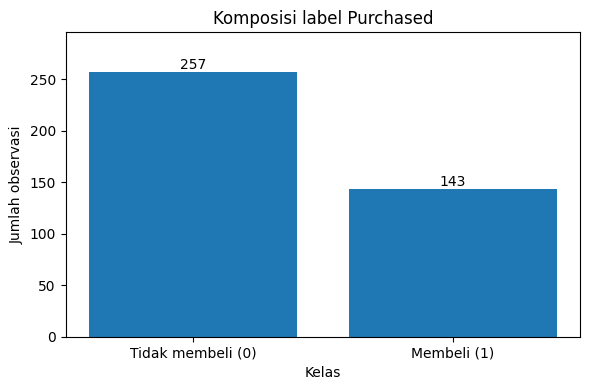

In [19]:
label_counts = ads['Purchased'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['Tidak membeli (0)', 'Membeli (1)'], label_counts.values)
ax.set(title='Komposisi label Purchased', xlabel='Kelas', ylabel='Jumlah observasi')
for i, v in enumerate(label_counts.values):
    ax.text(i, v + 3, str(v), ha='center')
ax.set_ylim(0, label_counts.max() * 1.15)
plt.tight_layout()
plt.show()

**Interpretasi:** pada data ini kelas 0 lebih banyak daripada kelas 1. Grafik jumlah hanya menunjukkan *frekuensi*, belum menunjukkan performa model atau alasan seseorang melakukan pembelian.

### G2. Histogram — distribusi usia

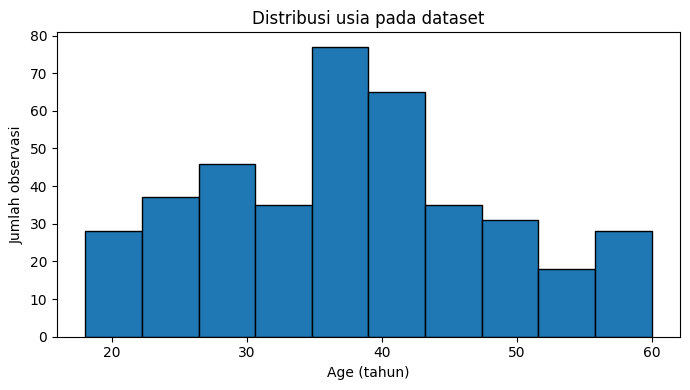

In [20]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(ads['Age'], bins=10, edgecolor='black')
ax.set(title='Distribusi usia pada dataset', xlabel='Age (tahun)', ylabel='Jumlah observasi')
plt.tight_layout()
plt.show()

**Interpretasi:** histogram menggambarkan jumlah observasi pada rentang usia; bentuk histogram dapat berubah bila jumlah *bins* diubah. Coba `bins=5` lalu `bins=15`, dan bandingkan visualisasinya.

### G3. Boxplot — sebaran estimasi gaji menurut kelas

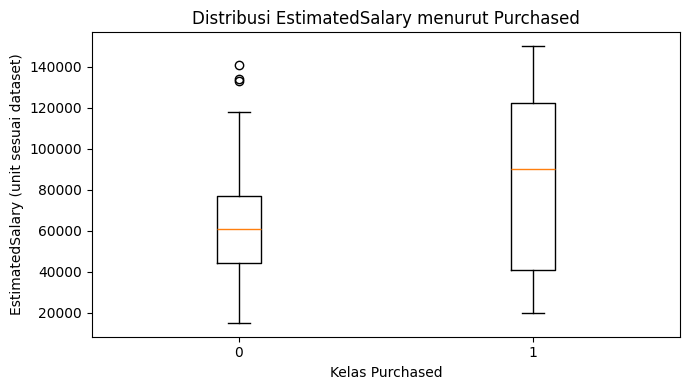

In [21]:
salary_by_class = [ads.loc[ads['Purchased'] == cls, 'EstimatedSalary'] for cls in (0, 1)]
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(salary_by_class, tick_labels=['0', '1'])
ax.set(title='Distribusi EstimatedSalary menurut Purchased',
       xlabel='Kelas Purchased', ylabel='EstimatedSalary (unit sesuai dataset)')
plt.tight_layout()
plt.show()

**Interpretasi:** garis dalam kotak menunjukkan median, batas kotak merepresentasikan kuartil pertama dan ketiga, sementara *whisker* dan penanda menunjukkan variasi data menurut aturan visualisasi. Nilai ekstrem yang terdeteksi grafis belum tentu salah atau harus dibuang.

### G4. Scatter plot — hubungan dua variabel numerik

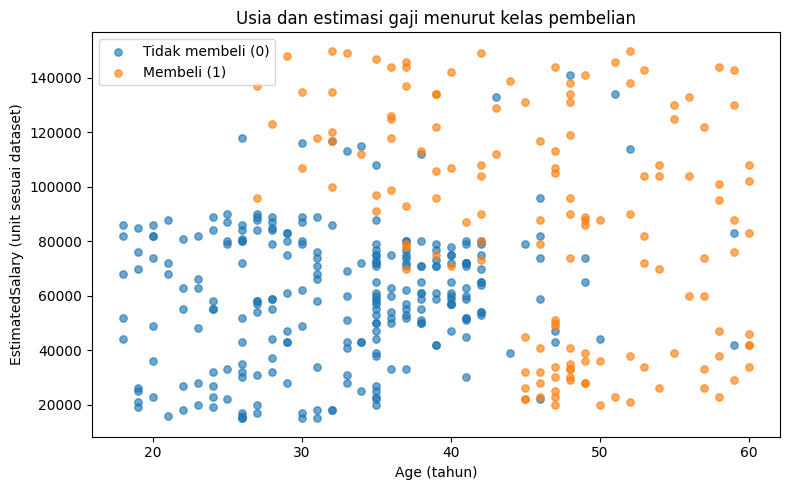

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
for cls, name in [(0, 'Tidak membeli (0)'), (1, 'Membeli (1)')]:
    subset = ads[ads['Purchased'] == cls]
    ax.scatter(subset['Age'], subset['EstimatedSalary'],
               label=name, alpha=0.65, s=28)
ax.set(title='Usia dan estimasi gaji menurut kelas pembelian',
       xlabel='Age (tahun)', ylabel='EstimatedSalary (unit sesuai dataset)')
ax.legend()
plt.tight_layout()
plt.show()

**Interpretasi:** satu titik merepresentasikan satu observasi (titik bisa saling menumpuk). Warna/legenda menunjukkan label. Pola visual dapat menjadi hipotesis awal, **bukan** kesimpulan bahwa hubungan itu kausal atau hasil model sudah akurat.

### G5. Perbandingan rata-rata usia per kelas

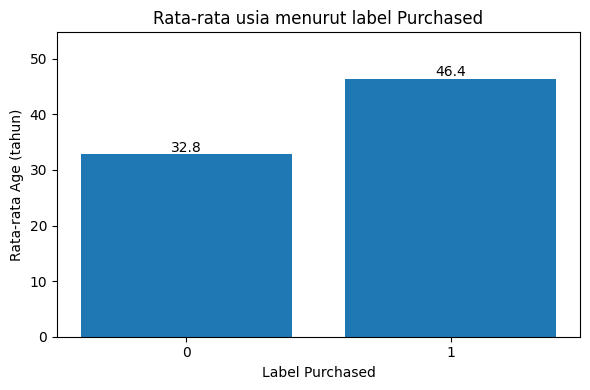

In [23]:
mean_age = ads.groupby('Purchased')['Age'].mean().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar([str(x) for x in mean_age.index], mean_age.values)
ax.set(title='Rata-rata usia menurut label Purchased',
       xlabel='Label Purchased', ylabel='Rata-rata Age (tahun)')
for i, value in enumerate(mean_age.values):
    ax.text(i, value + 0.5, f'{value:.1f}', ha='center')
ax.set_ylim(0, max(mean_age.values) * 1.18)
plt.tight_layout()
plt.show()

## H. Menentukan fitur dan target (pengenalan)

Kita **belum melatih model** pada Praktikum 01. Pada contoh klasifikasi, `Age` dan `EstimatedSalary` dapat dipilih sebagai masukan (`X`), sedangkan `Purchased` adalah target (`y`).

**Mengapa tidak memasukkan `Purchased` ke `X`?** Karena itu jawaban yang hendak diprediksi. Memasukkannya sebagai masukan membuat rancangan prediksi tidak valid. `User ID` juga tidak dipilih karena merupakan kode identitas, bukan atribut substantif yang didefinisikan sebagai prediktor.

In [24]:
feature_cols = ['Age', 'EstimatedSalary']
target_col = 'Purchased'

X = ads[feature_cols].copy()  # DataFrame: 400 baris x 2 kolom
y = ads[target_col].copy()    # Series  : 400 nilai label

print('Feature columns:', X.columns.tolist())
print('X.shape       :', X.shape)
print('y.shape       :', y.shape)
print('Sampel 1 (fitur):')
display(X.head(1))
print('Label sampel 1:', y.iloc[0])

Feature columns: ['Age', 'EstimatedSalary']
X.shape       : (400, 2)
y.shape       : (400,)
Sampel 1 (fitur):


,Age,EstimatedSalary
0,19,19000


Label sampel 1: 0


**Jembatan ke Modul 02:** `X.shape = (400, 2)` menunjukkan 400 sampel dan 2 fitur numerik pilihan. Pada Modul 02, kita akan mempelajari bagaimana representasi fitur berubah untuk data kategorikal, teks, dan gambar. Pada Modul 03, kita baru membahas pemisahan train/test dan preprocessing yang sesuai.

## I. Praktik terbimbing: rangkum hasil eksplorasi

Satukan informasi penting dalam satu ringkasan: jumlah observasi, missing value, komposisi label, rerata dan median fitur. Ini contoh **ringkasan EDA**, bukan laporan performa model.

In [25]:
ringkasan_eda = pd.Series({
    'Jumlah observasi': len(ads),
    'Jumlah kolom asli': ads.shape[1],
    'Nilai kosong total': int(ads.isna().sum().sum()),
    'Duplikat identik': int(ads.duplicated().sum()),
    'Usia minimum': int(ads['Age'].min()),
    'Usia maksimum': int(ads['Age'].max()),
    'Usia median': float(ads['Age'].median()),
    'Gaji median (unit dataset)': float(ads['EstimatedSalary'].median()),
    'Proporsi Purchased=1': round(ads['Purchased'].mean(), 4),
})
display(ringkasan_eda.to_frame('hasil'))

,hasil
Jumlah observasi,400.0000
Jumlah kolom asli,5.0000
Nilai kosong total,0.0000
Duplikat identik,0.0000
Usia minimum,18.0000
Usia maksimum,60.0000
Usia median,37.0000
Gaji median (unit dataset),70000.0000
Proporsi Purchased=1,0.3575


### Cek hasil dan keterbatasan

- Jumlah baris dan jumlah label harus konsisten dengan tabel mentah.
- Jangan mencampurkan **persentase** dengan **proporsi**: 0,3575 = 35,75%.
- Informasi tahun, populasi asal, dan mata uang tidak terdokumentasi dalam file asli; sebutkan keterbatasan tersebut saat melaporkan temuan.
- Eksplorasi belum melibatkan pembagian train/test, preprocessing, maupun pelatihan model.

In [26]:
assert tab.shape == (5, 4), 'Periksa pembacaan indeks Tab.csv'
assert ads.shape == (400, 5), 'Dataset Ads tidak sesuai dengan data latihan'
assert not X.isna().any().any(), 'Contoh X seharusnya tanpa nilai kosong'
assert set(y.unique()) == {0, 1}, 'Target seharusnya memiliki label 0 dan 1'
assert len(y) == len(X), 'Jumlah label harus sesuai jumlah sampel'
print('Pemeriksaan struktur dataset dan fitur: LULUS')

Pemeriksaan struktur dataset dan fitur: LULUS


## J. Latihan mandiri (kerjakan sebelum membuka kunci jawaban)

### J1. Pertanyaan pemahaman (10 soal)

1. Apa perbedaan `list`, NumPy `ndarray`, dan Pandas `DataFrame`?
2. Apa arti `shape = (400, 5)` pada DataFrame?
3. Apa perbedaan `.loc` dan `.iloc`? Gunakan `Tab.csv` sebagai contoh.
4. Mengapa `Tab.csv` dibaca dengan `index_col=0`?
5. Mengapa `User ID` tidak sebaiknya langsung diperlakukan sebagai nilai numerik substantif?
6. Apa perbedaan *mean* dan *median*? Kapan median lebih informatif?
7. Apa perbedaan pemeriksaan nilai kosong dengan imputasi?
8. Mengapa histogram dapat tampak berbeda meskipun data sama?
9. Mengapa perbedaan rata-rata `Age` menurut `Purchased` tidak membuktikan sebab-akibat?
10. Jika `Purchased` adalah target, mengapa ia tidak boleh menjadi bagian dari `X`?

### J2. Latihan kode (8 soal)

**L1.** Ambil dua nama negara pertama dari `tab` sebagai list.  
**L2.** Tampilkan nama negara dan ibu kota untuk kode indeks `JP`.  
**L3.** Tampilkan semua negara pada `Tab.csv` dengan nilai `Populasi` lebih dari 40, urut menurun.  
**L4.** Hitung nilai median `Age` dan rata-rata `EstimatedSalary`.  
**L5.** Hitung jumlah pengguna untuk masing-masing `Gender`.  
**L6.** Hitung persentase `Purchased=1` dari seluruh observasi.  
**L7.** Filter usia antara 30 dan 39 tahun (inklusif), lalu hitung jumlah observasi.  
**L8.** Buat tabel jumlah observasi serta proporsi `Purchased=1` per `Gender`.

### J3. Mini-proyek EDA

Buat tabel ringkas berisi kelompok usia `<30`, `30–44`, dan `45+`, kemudian hitung: jumlah observasi dan proporsi `Purchased=1` pada setiap kelompok. Visualisasikan jumlah observasi per kelompok usia menggunakan diagram batang. Tulis **dua temuan deskriptif dan satu keterbatasan**.

---

# Kunci jawaban dan pembahasan

> Bagian ini disediakan untuk dosen dan latihan mandiri. Seluruh jawaban kode menggunakan dataset yang sama; hasil angka yang disebutkan merujuk file asli paket workshop.

## K1. Jawaban pertanyaan pemahaman

1. **List** adalah koleksi Python umum; **ndarray** mendukung operasi numerik multidimensi; **DataFrame** adalah tabel berindeks dengan nama kolom dan tipe data per kolom.
2. Ada **400 baris** dan **5 kolom** pada DataFrame mentah, tidak berarti kelima kolom adalah fitur model.
3. `.loc` memakai **label indeks** (contoh: `tab.loc['JP']`); `.iloc` memakai **posisi baris** (contoh: `tab.iloc[3]`).
4. Karena kolom pertama berisi **kode negara**, lebih tepat dijadikan label indeks daripada atribut pengukuran.
5. `User ID` adalah pengenal catatan, sehingga operasi rata-rata/penjumlahan ID tidak merepresentasikan sifat pengguna yang substantif.
6. *Mean* adalah rata-rata aritmetika; *median* adalah nilai tengah urutan data. Median lebih tahan terhadap nilai ekstrem.
7. **Deteksi** mengukur keberadaan kekosongan; **imputasi** mengisi nilai kosong memakai metode tertentu. Kita baru melakukan deteksi di modul ini.
8. Histogram membagi rentang angka ke sejumlah *bins*; pilihan lebar/jumlah bins mengubah detail tampilan distribusi.
9. Kelompok mungkin berbeda karena faktor lain; observasi lintas kelompok tidak mengisolasi pengaruh kausal usia.
10. `Purchased` adalah jawaban yang ingin diprediksi sehingga menyertakannya sebagai masukan akan membocorkan label (*target leakage*).

## K2. Jawaban L1–L4

In [27]:
# L1 — Dua negara pertama
jawaban_l1 = tab['Negara'].head(2).tolist()
print('L1:', jawaban_l1)

# L2 — Baris negara Jepang, tampilkan dua kolom
jawaban_l2 = tab.loc[['JP'], ['Negara', 'Ibukota']]
print('L2:')
display(jawaban_l2)

# L3 — Filter dan urutkan nilai populasi latihan > 40
jawaban_l3 = (tab.loc[tab['Populasi'] > 40, ['Negara', 'Populasi']]
              .sort_values('Populasi', ascending=False))
print('L3:')
display(jawaban_l3)

# L4 — Median usia dan rata-rata gaji
print('L4 | Median Age:', ads['Age'].median())
print('L4 | Mean EstimatedSalary:', round(ads['EstimatedSalary'].mean(), 2))

L1: ['Indonesia', 'Malaysia']
L2:


,Negara,Ibukota
JP,Jepang,Tokyo


L3:


,Negara,Populasi
IN,Indonesia,250
JP,Jepang,60
TH,Thailand,45


L4 | Median Age: 37.0
L4 | Mean EstimatedSalary: 69742.5


## K3. Jawaban L5–L8

In [28]:
# L5 — Banyak observasi menurut gender
print('L5:')
display(ads['Gender'].value_counts().rename('jumlah').to_frame())

# L6 — Persentase label 1
print('L6 | Persentase Purchased=1:', f"{ads['Purchased'].eq(1).mean() * 100:.2f}%")

# L7 — Usia 30 sampai 39 inklusif
seleksi_usia = ads.loc[ads['Age'].between(30, 39)]
print('L7 | Jumlah usia 30–39:', len(seleksi_usia))

# L8 — Banyak sampel dan proporsi label 1 per gender
jawaban_l8 = (ads.groupby('Gender')
              .agg(jumlah=('Purchased', 'size'),
                   proporsi_membeli=('Purchased', 'mean'))
              .round(4))
print('L8:')
display(jawaban_l8)

L5:


,jumlah
Gender,
Female,204
Male,196


L6 | Persentase Purchased=1: 35.75%
L7 | Jumlah usia 30–39: 138
L8:


,jumlah,proporsi_membeli
Gender,,
Female,204,0.3775
Male,196,0.3367


## K4. Mini-proyek — solusi kode

`pd.cut()` dipakai untuk membuat kelompok usia. Interval harus dinyatakan dengan jelas agar batas usia (misalnya 30, 44, dan 45) tidak terhitung ganda atau terlewat.

,jumlah,pembeli,proporsi_membeli,persen_membeli
kelompok_usia,,,,
<30,100,4,0.040000,4.00
30–44,190,45,0.236842,23.68
45+,110,94,0.854545,85.45


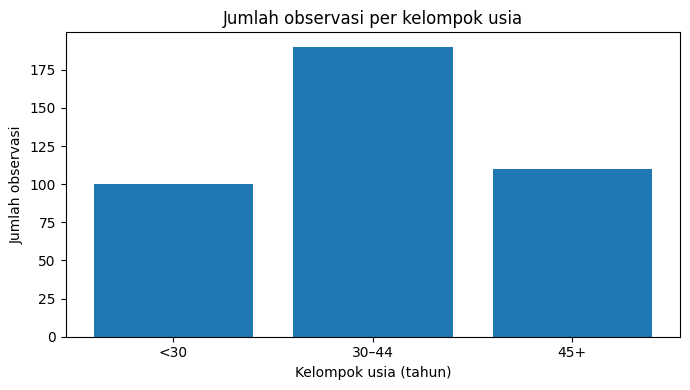

In [29]:
mini = ads.copy()
mini['kelompok_usia'] = pd.cut(
    mini['Age'],
    bins=[-np.inf, 29, 44, np.inf],
    labels=['<30', '30–44', '45+']
)

ringkasan_usia = (mini.groupby('kelompok_usia', observed=True)
                 .agg(jumlah=('Purchased', 'size'),
                      pembeli=('Purchased', 'sum'),
                      proporsi_membeli=('Purchased', 'mean')))
ringkasan_usia['persen_membeli'] = (100 * ringkasan_usia['proporsi_membeli']).round(2)
display(ringkasan_usia)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(ringkasan_usia.index.astype(str), ringkasan_usia['jumlah'])
ax.set(title='Jumlah observasi per kelompok usia',
       xlabel='Kelompok usia (tahun)', ylabel='Jumlah observasi')
plt.tight_layout()
plt.show()

### K5. Contoh interpretasi mini-proyek

1. **Temuan deskriptif 1:** kelompok usia dapat memiliki jumlah observasi yang tidak sama; bandingkan kolom `jumlah` sebelum menilai persentase pembelian.
2. **Temuan deskriptif 2:** kolom `persen_membeli` menunjukkan proporsi label 1 **di setiap kelompok usia**; pembaca harus membedakan proporsi tersebut dari jumlah absolut pembeli.
3. **Keterbatasan:** dataset tidak menyediakan rancangan sampling, waktu, dan konteks pengumpulan, sehingga hasil kelompok usia tidak boleh digeneralisasikan sebagai perilaku populasi ataupun hubungan kausal.

**Penilaian dosen (contoh rubrik, total 100):**

| Aspek | Bobot | Kriteria |
|---|---:|---|
| Ketepatan kode dan file | 30 | Semua perhitungan berasal dari dataset asli dan berhasil dijalankan |
| Ketepatan penyaringan serta agregasi | 25 | Rentang usia dan rumus proporsi benar |
| Visualisasi | 20 | Label sumbu, judul, dan tipe grafik sesuai |
| Interpretasi dan keterbatasan | 25 | Dua temuan terukur serta satu keterbatasan yang relevan |

## L. Rangkuman sebelum masuk ke Praktikum 02

- Python dasar mengelola variabel, koleksi, logika, dan fungsi.
- NumPy memudahkan operasi numerik pada array 1D dan 2D.
- Pandas mengelola data tabular dan mendukung inspeksi, filter, pengurutan, serta agregasi.
- EDA membantu memahami distribusi, komposisi kelas, dan masalah kualitas yang teramati.
- Grafik harus diberi label yang jelas dan ditafsirkan dengan batasan yang tepat.
- `X` adalah fitur masukan, `y` adalah target; keduanya **belum** digunakan untuk training pada modul ini.

**Checkpoint:** bila Anda dapat menjelaskan `shape`, `dtype`, `.loc`, `.iloc`, `groupby`, dan perbedaan fitur–target dengan contoh, lanjutkan ke **Praktikum 02 — Input Space dan Feature Space**.